# 1. Setup & Imports
Import core data science, signal/feature utilities, imbalanced-learning tools, and TensorFlow/Keras for the 1D CNN. Fix random seeds for reproducibility.

In [1]:
# Install if needed:
# !pip install numpy pandas scikit-learn imbalanced-learn tensorflow matplotlib scipy
%pip install tensorflow

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import medfilt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
)
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

Note: you may need to restart the kernel to use updated packages.


# 2. Load Local CSV Dataset (`exoTrain.csv` & `exoTest.csv`)
Load the Kaggle Kepler labeled time-series CSVs located in the working directory.
- Column `LABEL`: `2` = confirmed exoplanet (`1` after mapping), `1` = non-exoplanet / false positive (`0` after mapping).
- Remaining `3,197` columns: stellar flux time-series points per star.

In [2]:
# Update paths if your notebook is not inside the 'NASA Kepler 1D' folder
TRAIN_PATH = "exoTrain.csv"
TEST_PATH = "exoTest.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

# Map labels: original (1, 2) -> binary (0, 1)
y_train = (train_df["LABEL"].values == 2).astype(int)
y_test = (test_df["LABEL"].values == 2).astype(int)

X_train_raw = train_df.drop(columns=["LABEL"]).values.astype(np.float32)
X_test_raw = test_df.drop(columns=["LABEL"]).values.astype(np.float32)

print(f"Train shape: {X_train_raw.shape} | Exoplanets (1): {y_train.sum()} / {len(y_train)}")
print(f"Test  shape: {X_test_raw.shape} | Exoplanets (1): {y_test.sum()} / {len(y_test)}")

Train shape: (5087, 3197) | Exoplanets (1): 37 / 5087
Test  shape: (570, 3197) | Exoplanets (1): 5 / 570


# 3. Detrending & Domain Feature Extraction (Without Data Leakage)
Each star's light curve is processed independently (row-wise):
1. Lightly smooth with a median filter to suppress single-point spikes while keeping transit dips.
2. Extract domain features (minimum/dip depth, flux spread, skewness, and odd-vs-even dip asymmetry) for a tabular baseline.
3. Normalize each light curve row-wise so brightness scale differences don't dominate the 1D CNN.

In [3]:
def preprocess_light_curves(flux_matrix: np.ndarray, kernel_size: int = 11):
    """Row-wise detrend/smooth, extract domain features, and normalize sequences."""
    n_stars, n_pts = flux_matrix.shape
    norm_seqs = np.zeros((n_stars, n_pts), dtype=np.float32)
    tab_features = np.zeros((n_stars, 6), dtype=np.float32)

    for i in range(n_stars):
        row = np.nan_to_num(flux_matrix[i], nan=np.nanmedian(flux_matrix[i]))

        # Smooth slightly to reduce single-sample noise while preserving transit dips
        smoothed = medfilt(row, kernel_size=kernel_size)
        residual = row - smoothed

        med_val = np.median(smoothed)
        std_val = np.std(smoothed) + 1e-8
        norm_flux = (smoothed - med_val) / std_val
        norm_seqs[i] = norm_flux

        # Feature 1-3: dip depth (min), spread (std), and negative skew (transit dips pull left)
        min_dip = float(np.min(norm_flux))
        flux_std = float(np.std(row))
        centered = norm_flux - np.mean(norm_flux)
        skew_val = float(np.mean(centered**3) / (np.std(centered)**3 + 1e-8))

        # Feature 4: high-frequency noise level
        noise_std = float(np.std(residual))

        # Feature 5-6: odd vs. even segment minimum depth (helps spot asymmetric/binary dips)
        half = n_pts // 2
        odd_min = float(np.min(norm_flux[:half]))
        even_min = float(np.min(norm_flux[half:2 * half]))
        odd_even_diff = abs(odd_min - even_min)
        deeper_dip = min(odd_min, even_min)

        tab_features[i] = [min_dip, flux_std, skew_val, noise_std, odd_even_diff, deeper_dip]

    feature_names = ["min_dip", "flux_std", "skew", "noise_std", "odd_even_diff", "deeper_dip"]
    return tab_features, norm_seqs, feature_names


X_tr_tab, X_tr_seq, feat_names = preprocess_light_curves(X_train_raw, kernel_size=11)
X_te_tab, X_te_seq, _ = preprocess_light_curves(X_test_raw, kernel_size=11)

print("Extracted tabular features:", feat_names)
print("Normalized sequence shape:", X_tr_seq.shape)

Extracted tabular features: ['min_dip', 'flux_std', 'skew', 'noise_std', 'odd_even_diff', 'deeper_dip']
Normalized sequence shape: (5087, 3197)


# 4. Feature Scaling & Training-Only Class Imbalance Handling
Fit `StandardScaler` **only** on training tabular features, then transform test features. Apply `SMOTE` **only** to the training sequences so validation/test data remain untouched and leak-free.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Scale tabular features strictly on training set
scaler = StandardScaler()
X_tr_tab_s = scaler.fit_transform(X_tr_tab)
X_te_tab_s = scaler.transform(X_te_tab)

# 2. Carve out a clean stratified validation split BEFORE SMOTE so val metrics aren't inflated
X_tr_seq_sub, X_val_seq, y_tr_sub, y_val = train_test_split(
    X_tr_seq,
    y_train,
    test_size=0.2,
    stratify=y_train if np.min(np.bincount(y_train)) >= 2 else None,
    random_state=SEED,
)

# 3. Apply mild SMOTE ONLY to the training sub-split (sampling_strategy=0.25 avoids heavy synthetic noise)
min_pos = int(np.sum(y_tr_sub == 1))
if min_pos > 1:
    k_neighbors = min(3, min_pos - 1)
    smote = SMOTE(sampling_strategy=0.25, k_neighbors=k_neighbors, random_state=SEED)
    X_tr_seq_res, y_tr_res = smote.fit_resample(X_tr_seq_sub, y_tr_sub)
else:
    X_tr_seq_res, y_tr_res = X_tr_seq_sub.copy(), y_tr_sub.copy()

# 4. Reshape sequences for Conv1D: (samples, timesteps, channels)
X_tr_seq_in = X_tr_seq_res[..., np.newaxis]
X_val_seq_in = X_val_seq[..., np.newaxis]
X_te_seq_in = X_te_seq[..., np.newaxis]

print(f"Train (post-mild-SMOTE): {len(y_tr_res)} (Positives: {y_tr_res.sum()}, Negatives: {(y_tr_res == 0).sum()})")
print(f"Clean Val set:           {len(y_val)} (Positives: {y_val.sum()}, Negatives: {(y_val == 0).sum()})")
print(f"Test set:                {len(y_test)} (Positives: {y_test.sum()}, Negatives: {(y_test == 0).sum()})")

Train (post-mild-SMOTE): 5048 (Positives: 1009, Negatives: 4039)
Clean Val set:           1018 (Positives: 7, Negatives: 1011)
Test set:                570 (Positives: 5, Negatives: 565)


# 5. Train Baseline Model vs. 1D CNN & Evaluate with PR-AUC
Because exoplanets are rare, **Precision-Recall AUC (PR-AUC)** is more informative than raw accuracy. Compare a `HistGradientBoostingClassifier` baseline on extracted features against a 1D CNN on the full light curve.

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
)
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Baseline Model: HistGradientBoostingClassifier on engineered features
pos_weight_full = (len(y_train) - y_train.sum()) / max(y_train.sum(), 1)
tr_weights_full = np.where(y_train == 1, pos_weight_full, 1.0)

hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED)
hgb.fit(X_tr_tab_s, y_train, sample_weight=tr_weights_full)
hgb_probs = hgb.predict_proba(X_te_tab_s)[:, 1]

# 2. 1D CNN Model on normalized light curve sequences
cnn = models.Sequential([
    layers.Input(shape=(X_tr_seq_in.shape[1], 1)),
    layers.Conv1D(16, kernel_size=15, strides=2, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4),

    layers.Conv1D(32, kernel_size=11, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=4),

    layers.Conv1D(64, kernel_size=7, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),

    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision"),
    ],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True
)

history = cnn.fit(
    X_tr_seq_in,
    y_tr_res,
    validation_data=(X_val_seq_in, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1,
)

# 3. Tune classification threshold on the clean validation set (maximizing F1)
val_probs = cnn.predict(X_val_seq_in, verbose=0).ravel()
cnn_probs = cnn.predict(X_te_seq_in, verbose=0).ravel()

prec_v, rec_v, thresh_v = precision_recall_curve(y_val, val_probs)
if len(thresh_v) > 0:
    denom = prec_v[:-1] + rec_v[:-1]
    f1_v = np.where(denom > 0, 2 * prec_v[:-1] * rec_v[:-1] / denom, 0.0)
    best_thresh = float(thresh_v[int(np.argmax(f1_v))])
else:
    best_thresh = 0.5

print(f"\nTuned Validation Threshold (max F1): {best_thresh:.3f}")
print(f"Test PR-AUC — Baseline (HistGradientBoosting): {average_precision_score(y_test, hgb_probs):.4f}")
print(f"Test PR-AUC — 1D CNN:                      {average_precision_score(y_test, cnn_probs):.4f}\n")

cnn_preds = (cnn_probs >= best_thresh).astype(int)
print(f"1D CNN Classification Report (threshold={best_thresh:.3f}):")
print(classification_report(y_test, cnn_preds, target_names=["Non-Planet (0)", "Exoplanet (1)"], digits=3))
print("Confusion Matrix:\n", confusion_matrix(y_test, cnn_preds))

Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - loss: 0.4840 - pr_auc: 0.5315 - precision: 0.5272 - recall: 0.6056 - val_loss: 0.4495 - val_pr_auc: 0.0331 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 0.3272 - pr_auc: 0.7458 - precision: 0.7570 - recall: 0.6670 - val_loss: 0.4427 - val_pr_auc: 0.1497 - val_precision: 0.0185 - val_recall: 0.1429
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - loss: 0.2015 - pr_auc: 0.9139 - precision: 0.8749 - recall: 0.8593 - val_loss: 0.5528 - val_pr_auc: 0.0205 - val_precision: 0.0140 - val_recall: 0.4286
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.1297 - pr_auc: 0.9618 - precision: 0.9104 - recall: 0.9058 - val_loss: 0.7079 - val_pr_auc: 0.0310 - val_precision: 0.0134 - val_recall: 0.8571
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - loss: 0.0872 - pr_auc: 0.9847 - precision: 0.9337 - recall: 0.9485 - val_loss: 0.4923 - val_pr_auc: 0.0778 - val_precis

# 6. Error Analysis & Diagnostic Plots
Inspect false positives and false negatives, inspect the Precision-Recall curve, and plot a sample light curve from the test set.

False Positives: 1 | False Negatives: 2

Sample False Positives:
   min_dip   flux_std       skew  noise_std  odd_even_diff  deeper_dip  true_label  cnn_prob  cnn_pred
-21.922386 185.796265 -19.698339 148.167755      21.138027  -21.922386           0  0.909568         1

Sample False Negatives:
   min_dip   flux_std      skew  noise_std  odd_even_diff  deeper_dip  true_label  cnn_prob  cnn_pred
 -2.591559  29.811802  0.564016  18.965147       0.101531   -2.591559           1  0.063266         0
-13.638476 177.015320 -6.808412 143.518494      10.912085  -13.638476           1  0.026877         0


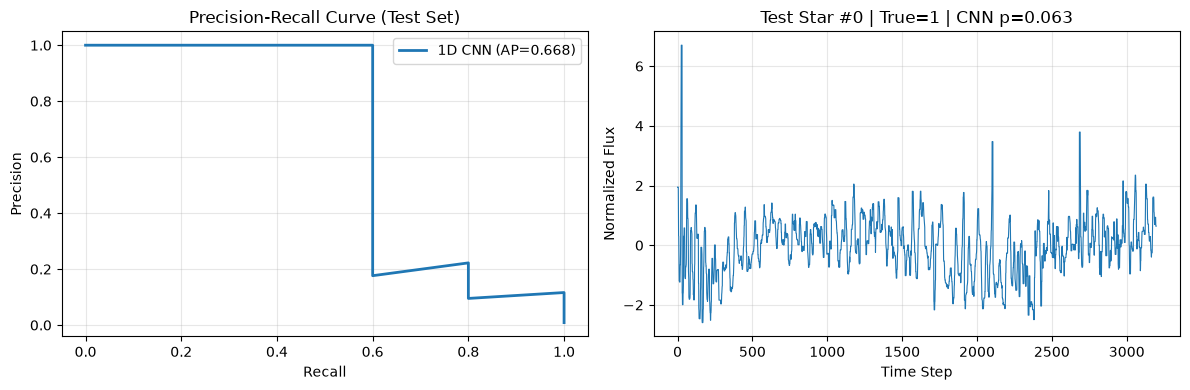

In [7]:
test_eval_df = pd.DataFrame(X_te_tab, columns=feat_names)
test_eval_df["true_label"] = y_test
test_eval_df["cnn_prob"] = cnn_probs
test_eval_df["cnn_pred"] = cnn_preds

false_positives = test_eval_df[(test_eval_df["true_label"] == 0) & (test_eval_df["cnn_pred"] == 1)]
false_negatives = test_eval_df[(test_eval_df["true_label"] == 1) & (test_eval_df["cnn_pred"] == 0)]

print(f"False Positives: {len(false_positives)} | False Negatives: {len(false_negatives)}")
if len(false_positives) > 0:
    print("\nSample False Positives:")
    print(false_positives.head(5).to_string(index=False))
if len(false_negatives) > 0:
    print("\nSample False Negatives:")
    print(false_negatives.head(5).to_string(index=False))

# Plot PR curve + sample test light curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

prec, rec, _ = precision_recall_curve(y_test, cnn_probs)
axes[0].plot(rec, prec, lw=2, label=f"1D CNN (AP={average_precision_score(y_test, cnn_probs):.3f})")
axes[0].set_title("Precision-Recall Curve (Test Set)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Pick first true exoplanet in test set if present, else index 0
pos_indices = np.where(y_test == 1)[0]
sample_idx = int(pos_indices[0]) if len(pos_indices) > 0 else 0
axes[1].plot(X_te_seq[sample_idx], lw=0.8)
axes[1].set_title(
    f"Test Star #{sample_idx} | True={y_test[sample_idx]} | CNN p={cnn_probs[sample_idx]:.3f}"
)
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Normalized Flux")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()